In [57]:
import matplotlib.pyplot as plt
import numpy as np

# Small worked example

In [22]:
# Pick 5 random points in the unit square
np.random.seed(42)
n = 5
points = np.random.rand(n, 2)
print("Random points in the unit square:")
print(points)

Random points in the unit square:
[[0.37454012 0.95071431]
 [0.73199394 0.59865848]
 [0.15601864 0.15599452]
 [0.05808361 0.86617615]
 [0.60111501 0.70807258]]


In [23]:
# Count how many are in the unit circle
in_circle = np.sum(points**2, axis=1) <= 1
in_circle_count = np.sum(in_circle)
print("Number of points in the unit circle:", in_circle_count)

# Estimate the value of pi using the ratio of points inside the circle to total points
pi_estimate = 4 * in_circle_count / len(points)
print("Estimated value of pi:", pi_estimate)

Number of points in the unit circle: 4
Estimated value of pi: 3.2


In [30]:
# Coordinate-wise sample variance
sample_variance = np.var(points, axis=0, ddof=1)
print("Sample variance of the points:", sample_variance)

# Pi estimate sample variance
pi_estimate_variance = np.var(4 * in_circle, ddof=1) / n
print("Sample variance of the pi estimate:", pi_estimate_variance)

# Confidence interval for the pi estimate
stderr = np.sqrt(pi_estimate_variance)
z = 1.96
ci_lower, ci_upper = pi_estimate - z * stderr, pi_estimate + z * stderr
print(f"95% CI: [{ci_lower:.4f}, {ci_upper:.4f}]")

Sample variance of the points: [0.08163114 0.0967589 ]
Sample variance of the pi estimate: 0.6400000000000002
95% CI: [1.6320, 4.7680]


In [31]:
# Approximate error of the pi estimate
approx_error = np.abs(pi_estimate - np.pi)
print("Approximate error of the pi estimate:", approx_error)

Approximate error of the pi estimate: 0.05840734641020706


# Implementation

In [51]:
def estimate_pi(n, rng):
    # Generate n random (x, y) points in the unit square
    points = rng.random((n, 2))

    # Evaluating the indicator function 1(x^2 + y^2 <= 1)
    in_circle = np.sum(points**2, axis=1) <= 1

    # Estimate pi using the ratio of points inside the circle to total points
    in_circle_count = np.sum(in_circle)
    pi_estimate = 4 * in_circle_count / n

    # Find the sample variance of the estimate
    pi_estimate_variance = np.var(4 * in_circle, ddof=1) / n

    # Find the confidence interval based on the variance
    stderr = np.sqrt(pi_estimate_variance)
    z = 1.96
    ci_lower, ci_upper = pi_estimate - z * stderr, pi_estimate + z * stderr

    return pi_estimate, (ci_lower, ci_upper)

# Test

In [54]:
rng = np.random.default_rng(42)
for n in [1e1, 1e2, 1e3, 1e4, 1e6, 1e8]:
    n = int(n)
    pi_estimate, ci = estimate_pi(n, rng)
    print(f"n = {n:,}")
    print(f"pi estimate = {pi_estimate}")
    print(f"95% CI = {ci[0]:.4f}, {ci[1]:.4f}")
    approx_error = np.abs(pi_estimate - np.pi)
    print(f"Approximate error = {approx_error}")
    print()

n = 10
pi estimate = 2.4
95% CI = 1.1197, 3.6803
Approximate error = 0.7415926535897932

n = 100
pi estimate = 3.08
95% CI = 2.7484, 3.4116
Approximate error = 0.061592653589793045

n = 1,000
pi estimate = 3.124
95% CI = 3.0214, 3.2266
Approximate error = 0.017592653589793006

n = 10,000
pi estimate = 3.1544
95% CI = 3.1224, 3.1864
Approximate error = 0.012807346410206755

n = 1,000,000
pi estimate = 3.143088
95% CI = 3.1399, 3.1463
Approximate error = 0.001495346410206988

n = 100,000,000
pi estimate = 3.14161476
95% CI = 3.1413, 3.1419
Approximate error = 2.210641020683468e-05



This is the code given in the assignment sheet exactly. Note: not sure if we need this exact code or what it is supposed to do.

In [ ]:
from scipy import integrate # check only

rng = np.random.default_rng(0)
f, n, R = np.exp, 1000, 2000
I_lib = integrate.quad(f, 0, 1)[0]

sm = np.array([my_sample_mean(f, n, rng) for _ in range(R)]) # (est, s)
hm = np.array([my_hit_or_miss(f, np.e, n, rng) for _ in range(R)])

print(I_lib, np.e - 1)
print(n * sm[:, 0].var(), (np.e**2 - 1) / 2 - (np.e - 1)**2) # Q5
print(n * hm[:, 0].var(), np.e - 1)
lo, hi = sm[:, 0] - 1.96 * sm[:, 1] / np.sqrt(n), sm[:, 0] + 1.96 * sm[:, 1] / np.sqrt(n)
print(np.mean((lo <= I_lib) & (I_lib <= hi))) # Q2-style coverage

# Assumptions

1. We assume that NumPy provides a proper pRNG, which means each trial is independantly and identically distributed. This also means that we are assuming the distribution behaves like $U(0,1)$.

2. We assume that n is large enough for the central limit theorem to apply.

# test assumption 2?

# Iteration 3 Math Questions

## 1

This was completed in latex and in the "Small worked example section"

## 2

In [ ]:
contains_pi = 0
for _ in range(1_000):
    pi_estimate, ci = estimate_pi(1_000, rng)
    if ci[0] <= np.pi <= ci[1]:
        contains_pi += 1
print(f"Proportion of intervals containing pi: {contains_pi / 1_000}")

Proportion of intervals containing pi: 0.953


## 3

Fit line: slope = -0.5796273210369585, intercept = 0.24046676393434568


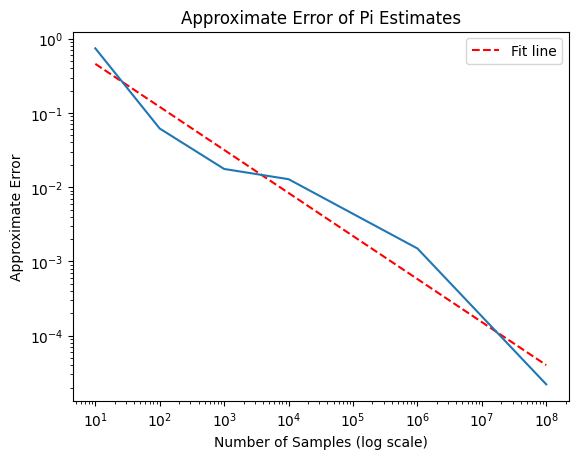

In [66]:
rng = np.random.default_rng(42)
error = []
n_values = [1e1, 1e2, 1e3, 1e4, 1e6, 1e8]
for n in n_values:
    n = int(n)
    pi_estimate, ci = estimate_pi(n, rng)
    approx_error = np.abs(pi_estimate - np.pi)
    error.append(approx_error)

# fit line
m, b = np.polyfit(np.log10(n_values), np.log10(error), 1)
print(f"Fit line: slope = {m}, intercept = {b}")

plt.plot(n_values, 10**(m * np.log10(n_values) + b), linestyle="--", color="red", label="Fit line")
plt.plot(n_values, error)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Number of Samples (log scale)")
plt.ylabel("Approximate Error")
plt.title("Approximate Error of Pi Estimates")
plt.legend()
plt.show()